# 05 · Robustness checks

Re-estimates the H3 baseline (labour share on lagged log real IPP capital per worker, with the finance interaction, two-way FE, clustered SEs) under alternative choices:

1. **Measures:** nominal IPP stock per worker; IPP investment per worker; IPP share of fixed assets; and the original IPP ÷ value added (subject to division bias, shown for comparison).
2. **Samples:** excluding COVID years; excluding IT-producing industries; balanced panel only; re-adding Funds, trusts & other financial vehicles (525), which is excluded from the main sample because its value added is tiny and erratic.
3. **Dynamics:** two-year lag; 5-year long differences.
4. **Weighting:** value-added-weighted regression.
5. **Outcome not based on value added:** real pay per FTE (addresses the measurement problems of financial-sector output).
6. **Placebo:** IPP capital per worker randomly reshuffled across industries within each year (500 draws).
6b. **Randomization inference:** the finance label reassigned to 1,000 random groups of industries, testing whether the finance difference could arise by chance from any three industries.
7. **Lead test:** future IPP capital per worker should not "predict" today's labour share once the current level is controlled for. (With IPP ÷ value added this test failed, which revealed the division bias.)
8. **Cross-source check:** BEA FTE vs BLS CES employment for finance sub-sectors.

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd()
while not (ROOT / "src" / "exgap").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)

In [2]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from exgap.build_panel import load_panel
from exgap import stats as st
from exgap.config import COVID_YEARS, RANDOM_STATE, PROCESSED_DIR
st.set_style()
base = load_panel().sort_values(["code", "year"])

TREAT = "log_ipp_pw"      # main treatment: log real IPP capital per worker

def prep(df, intensity=TREAT, lag=1):
    df = df.sort_values(["code", "year"]).copy()
    df["X"] = df.groupby("code")[intensity].shift(lag)
    df["finX"] = df["finance"] * df["X"]
    df["L_eq"] = df.groupby("code")["log_eq_pw"].shift(lag)
    return df

CTRL = ["L_eq"]

def run(df, label, y="labor_share", weights=None, **kw):
    from linearmodels.panel import PanelOLS
    xs = ["X", "finX"] + CTRL
    d = df.dropna(subset=[y] + xs).set_index(["code", "year"])
    w = d[weights] if weights else None
    res = PanelOLS(d[y], d[xs], entity_effects=True, time_effects=True, weights=w, drop_absorbed=True,
                   check_rank=False).fit(cov_type="clustered", cluster_entity=True)
    b, V = res.params, res.cov
    fin = b["X"] + b["finX"]
    se_fin = np.sqrt(V.loc["X", "X"] + V.loc["finX", "finX"] + 2 * V.loc["X", "finX"])
    return {"check": label, "beta_nonfinance": b["X"], "se_nonfinance": res.std_errors["X"], "p_nonfinance": res.pvalues["X"],
            "beta_finance": fin, "se_finance": se_fin, "nobs": int(res.nobs)}

rows = [run(prep(base), "Baseline")]
_run = run
def run(df, label, **kw):
    """Fail-safe wrapper: a check that cannot be estimated is reported, not fatal."""
    try:
        return _run(df, label, **kw)
    except Exception as e:
        print(f"  check '{label}' could not be estimated: {type(e).__name__}")
        return {"check": label}
print(pd.DataFrame(rows).round(4))

      check  beta_nonfinance  se_nonfinance  p_nonfinance  beta_finance  \
0  Baseline           0.0165         0.0142        0.2444       -0.0399   

   se_finance  nobs  
0      0.0125  1728  


## 1–5. Alternative measures, samples, dynamics, weighting and outcome

In [3]:
rows.append(run(prep(base, "log_ipp_pw_nom"), "Measure: nominal IPP stock per worker"))
if "log_ipp_inv_pw" in base:
    rows.append(run(prep(base, "log_ipp_inv_pw"), "Measure: IPP investment per worker"))
if "ipp_share_of_capital" in base:
    rows.append(run(prep(base, "ipp_share_of_capital"), "Measure: IPP share of fixed assets"))
rows.append(run(prep(base, "log_ipp_intensity"), "Measure: IPP / value added (division bias)"))
rows.append(run(prep(base[~base.year.isin(COVID_YEARS)]), "Sample: excl. COVID years"))
rows.append(run(prep(base[base.it_producing == 0]), "Sample: excl. IT-producing industries"))
# balanced panel: industries observed in every year of the most common coverage window
obs = base.dropna(subset=["labor_share", TREAT])
n_years = obs.groupby("code").year.nunique()
keep = n_years[n_years >= n_years.mode().iloc[0]].index
common_years = set.intersection(*[set(obs.loc[obs.code == c, "year"]) for c in keep])
bal = base[base.code.isin(keep) & base.year.isin(common_years | {min(common_years) - 1})]
rows.append(run(prep(bal), f"Sample: balanced panel ({len(keep)} industries)"))
rows.append(run(prep(load_panel(main_only=False)), "Sample: incl. funds & trusts (525)"))
rows.append(run(prep(base, lag=2), "Dynamics: two-year lag"))
rows.append(run(prep(base), "Weighting: value-added weights", weights="va_nom"))
tmp = base.copy(); tmp["log_pay_real_y"] = tmp["log_pay_real"]
rows.append(run(prep(tmp), "Outcome: log real pay per FTE", y="log_pay_real_y"))

# 5-year long differences (non-overlapping)
ld = base.dropna(subset=["labor_share", TREAT]).copy()
ld = ld[(ld.year - ld.year.min()) % 5 == 0].sort_values(["code", "year"])
ld["dY"] = ld.groupby("code")["labor_share"].diff(); ld["dX"] = ld.groupby("code")[TREAT].diff()
ld["dfinX"] = ld["finance"] * ld["dX"]
r = st.panel_fe(ld, "dY", ["dX", "dfinX"], entity_effects=False, time_effects=True)
V = r.cov
rows.append({"check": "Dynamics: 5-year long differences", "beta_nonfinance": r.params["dX"], "se_nonfinance": r.std_errors["dX"],
             "p_nonfinance": r.pvalues["dX"], "beta_finance": r.params["dX"] + r.params["dfinX"],
             "se_finance": np.sqrt(V.loc["dX", "dX"] + V.loc["dfinX", "dfinX"] + 2 * V.loc["dX", "dfinX"]), "nobs": int(r.nobs)})
rob = pd.DataFrame(rows).set_index("check")
rob.round(4)

,beta_nonfinance,se_nonfinance,p_nonfinance,beta_finance,se_finance,nobs
check,,,,,,
Baseline,0.0165,0.0142,0.2444,-0.0399,0.0125,1728
Measure: nominal IPP stock per worker,0.0116,0.0141,0.4116,-0.0640,0.0161,1728
Measure: IPP investment per worker,0.0126,0.0077,0.1003,-0.0409,0.0104,1728
Measure: IPP share of fixed assets,-0.2110,0.1072,0.0492,-0.9492,0.1859,1701
Measure: IPP / value added (division bias),0.0498,0.0127,0.0001,-0.0781,0.0172,1728
Sample: excl. COVID years,0.0194,0.0150,0.1967,-0.0384,0.0132,1600
Sample: excl. IT-producing industries,0.0271,0.0129,0.0364,-0.0294,0.0118,1566
Sample: balanced panel (64 industries),0.0165,0.0142,0.2444,-0.0399,0.0125,1728
Sample: incl. funds & trusts (525),0.0275,0.0157,0.0796,0.1231,0.0812,1755


## 6. Placebo: reshuffled IPP intensity
If the baseline result reflects a real relationship, coefficients estimated on randomly reassigned intensities should cluster around zero, and the true coefficient should lie in the tail.

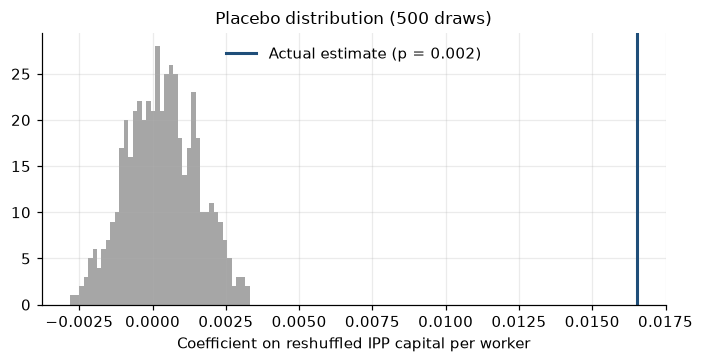

In [4]:
rng = np.random.default_rng(RANDOM_STATE)
true = rows[0]["beta_nonfinance"]
draws = []
B = 500
for b in range(B):
    sh = base.copy()
    sh[TREAT] = sh.groupby("year")[TREAT].transform(lambda s: rng.permutation(s.values))
    try:
        draws.append(run(prep(sh), "placebo")["beta_nonfinance"])
    except Exception:
        pass
draws = np.array(draws)
p_placebo = (np.sum(np.abs(draws) >= abs(true)) + 1) / (len(draws) + 1)
fig, ax = plt.subplots(figsize=(6.5, 3.4))
ax.hist(draws, bins=40, color=st.PALETTE["other"]); ax.axvline(true, color=st.PALETTE["finance"], lw=2, label=f"Actual estimate (p = {p_placebo:.3f})")
ax.set_xlabel("Coefficient on reshuffled IPP capital per worker"); ax.legend(); ax.set_title(f"Placebo distribution ({len(draws)} draws)")
st.savefig(fig, "fig13_placebo"); plt.show()
rob.loc["Placebo (permutation p-value)", ["beta_nonfinance", "p_nonfinance"]] = [np.mean(draws), p_placebo]

## 6b. Randomization inference for the finance difference

The finance interaction is identified from only three finance industries, so standard errors clustered by industry may be unreliable for it. This test asks how unusual the finance result is. It reassigns the "finance" label to 1,000 random sets of the same number of industries and re-estimates the interaction each time. The one-sided p-value is the share of random groups whose interaction is at least as negative as the real finance group's.

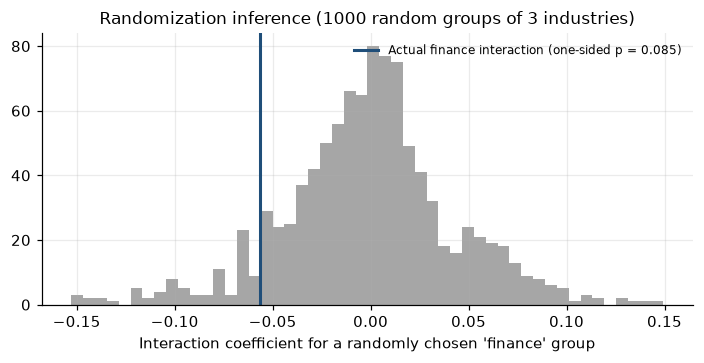

Actual interaction -0.0565; rank among random groups: 8.400% as negative or more


In [5]:
k = base.loc[base.finance == 1, "code"].nunique()
codes = base["code"].unique()
true_int = rows[0]["beta_finance"] - rows[0]["beta_nonfinance"]
ri = []
for b in range(1000):
    fake = rng.choice(codes, size=k, replace=False)
    sh = base.copy()
    sh["finance"] = sh["code"].isin(fake).astype(int)
    try:
        r_ = run(prep(sh), "ri")
        ri.append(r_["beta_finance"] - r_["beta_nonfinance"])
    except Exception:
        pass
ri = np.array(ri)
p_ri = (np.sum(ri <= true_int) + 1) / (len(ri) + 1)
fig, ax = plt.subplots(figsize=(6.5, 3.4))
ax.hist(ri, bins=50, color=st.PALETTE["other"])
ax.axvline(true_int, color=st.PALETTE["finance"], lw=2, label=f"Actual finance interaction (one-sided p = {p_ri:.3f})")
ax.set_xlabel("Interaction coefficient for a randomly chosen 'finance' group"); ax.legend(fontsize=8)
ax.set_title(f"Randomization inference ({len(ri)} random groups of {k} industries)")
st.savefig(fig, "fig13b_randomization_finance"); plt.show()
rob.loc["Randomization inference: finance label (one-sided p)", ["beta_finance", "p_nonfinance"]] = [true_int, p_ri]
print(f"Actual interaction {true_int:.4f}; rank among random groups: {np.mean(ri <= true_int):.3%} as negative or more")

## 7. Lead (pre-trend) test

In [6]:
lt = prep(base)
lt["LEAD2"] = lt.groupby("code")[TREAT].shift(-2)
r = st.panel_fe(lt, "labor_share", ["X", "LEAD2"] + CTRL)
lead_tab = st.tidy(r, "Lead test", keep=["X", "LEAD2"])
st.save_table(lead_tab.round(4), "robust_lead_test", index=False, caption="Lead test: future IPP capital per worker")
lead_tab.round(4)

,term,coef,se,t,p,ci_low,ci_high,model,nobs,n_entities,r2_within
0,X,0.0134,0.0241,0.5552,0.5788,-0.0339,0.0607,Lead test,1600,64,0.0516
1,LEAD2,0.0064,0.0166,0.3868,0.6989,-0.0262,0.0391,Lead test,1600,64,0.0516


## 8. Cross-source check: BEA FTE vs BLS CES employment (finance)

In [7]:
bls_file = PROCESSED_DIR / "bls_finance_checks.csv"
map_bea = {"522": "521CI", "523": "523", "524": "524"}
if bls_file.exists():
    bls = pd.read_csv(bls_file, dtype={"naics": str})
    emp = bls[(bls.measure == "employment") & bls.naics.isin(map_bea)].copy()
    emp["code"] = emp.naics.map(map_bea)
    m = emp.merge(base[["code", "year", "fte"]], on=["code", "year"], how="inner").sort_values(["code", "year"])
    m["g_bls"] = m.groupby("code")["value"].transform(lambda s: np.log(s).diff())
    m["g_bea"] = m.groupby("code")["fte"].transform(lambda s: np.log(s).diff())
    xcheck = m.dropna().groupby("code").apply(lambda g: pd.Series({"corr_growth": g.g_bls.corr(g.g_bea), "years": len(g)}))
    st.save_table(xcheck.round(3), "robust_bls_crosscheck", caption="BEA vs BLS employment growth, finance sub-sectors")
    display(xcheck.round(3))
else:
    print("BLS file not available - cross-check skipped.")

,corr_growth,years
code,,
521CI,0.952,27.0
523,0.954,27.0
524,0.807,27.0


## Summary table and figure

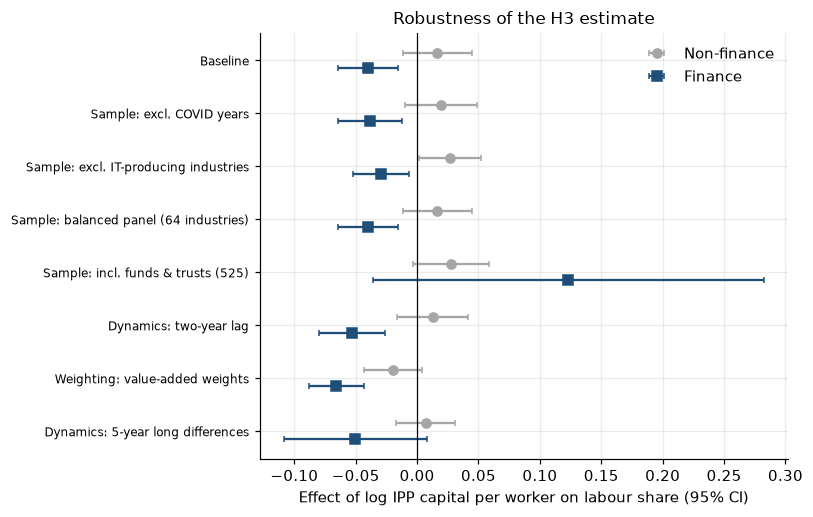

,beta_nonfinance,se_nonfinance,p_nonfinance,beta_finance,se_finance,nobs
check,,,,,,
Baseline,0.0165,0.0142,0.2444,-0.0399,0.0125,1728.0
Measure: nominal IPP stock per worker,0.0116,0.0141,0.4116,-0.0640,0.0161,1728.0
Measure: IPP investment per worker,0.0126,0.0077,0.1003,-0.0409,0.0104,1728.0
Measure: IPP share of fixed assets,-0.2110,0.1072,0.0492,-0.9492,0.1859,1701.0
Measure: IPP / value added (division bias),0.0498,0.0127,0.0001,-0.0781,0.0172,1728.0
Sample: excl. COVID years,0.0194,0.0150,0.1967,-0.0384,0.0132,1600.0
Sample: excl. IT-producing industries,0.0271,0.0129,0.0364,-0.0294,0.0118,1566.0
Sample: balanced panel (64 industries),0.0165,0.0142,0.2444,-0.0399,0.0125,1728.0
Sample: incl. funds & trusts (525),0.0275,0.0157,0.0796,0.1231,0.0812,1755.0


In [8]:
st.save_table(rob.round(4), "robustness_summary", caption="Robustness of the IPP-labour share relationship")
# plotted: checks that keep the baseline regressor (log IPP intensity) so coefficients share one scale
plot = rob.drop(index=[i for i in rob.index if i.startswith(("Placebo", "Outcome", "Measure", "Randomization"))]).copy()
fig, ax = plt.subplots(figsize=(7.5, 4.8))
y = np.arange(len(plot))
ax.errorbar(plot.beta_nonfinance, y - 0.15, xerr=1.96 * plot.se_nonfinance, fmt="o", color=st.PALETTE["other"], capsize=2, label="Non-finance")
ax.errorbar(plot.beta_finance, y + 0.15, xerr=1.96 * plot.se_finance.fillna(0), fmt="s", color=st.PALETTE["finance"], capsize=2, label="Finance")
ax.axvline(0, color="k", lw=0.8); ax.set_yticks(y); ax.set_yticklabels(plot.index, fontsize=8); ax.invert_yaxis()
ax.set_xlabel("Effect of log IPP capital per worker on labour share (95% CI)"); ax.legend()
ax.set_title("Robustness of the H3 estimate")
st.savefig(fig, "fig14_robustness"); plt.show()
rob.round(4)